In [1]:
### Dimensionality Reduction and Clustering
### November 23, 2026
### Jessica Zhang

In [2]:
### 1) Principle Components Analysis

# Libraries
import pandas as pd
import numpy as np
import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Use pandas to read the dataset csv file
df = pd.read_csv("/blue/env3040/jessicazhang1/Assignments/Li_et_al_2023_Gas_Exchange_Sheet.csv") 

# Create a variable containing the specific column's values
AOT40_ambient = df["AOT 40 - Ambient"]
AOT40_elevated = df["AOT 40 - Elevated"]
NPR_ambient = df["NPR - Ambient (umol m-2 s-1)"]
NPR_elevated = df["NPR - Elevated (umol m-2 s-1)"]
SC_ambient = df["SC - Ambient (mol m-2 s-1)"]
SC_elevated = df["SC - Elevated (mol m-2 s-1)"]
CO2_ambient = df["CO2 - Ambient (umol mol-1)"]
CO2_elevated = df["CO2 - Elevated (umol mol-1)"]

# Combined Ambient and Elevated variables into a single column
AOT40 = pd.concat([AOT40_ambient, AOT40_elevated])
NPR = pd.concat([NPR_ambient, NPR_elevated])
SC = pd.concat([SC_ambient, SC_elevated])
CO2 = pd.concat([CO2_ambient, CO2_elevated])

# Create a new dataframe
dfcombined = pd.DataFrame({
    "AOT40": AOT40.reset_index(drop=True),  # Resets the index so that every varaiable starts the same index
    "NPR": NPR.reset_index(drop=True),
    "SC": SC.reset_index(drop=True),
    "CO2": CO2.reset_index(drop=True)})

# Rescaling the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(dfcombined)    # rescales the data

# Creating PCA Analysis
pca = PCA(n_components=4)   # Create four principal components
pca_results = pca.fit_transform(scaled_data)   # Convert into PCA scores
explained_variance = pca.explained_variance_ratio_  # Calculates the four PCA explained variance

# Return the principal components explained variance
print("Explained Variance:", explained_variance)
print("PC1 variance: 0.52369993")
print("PC2 variance: 0.2903826")
print("PC3 variance: 0.17598698")
print("PC4 variance: 0.00993049")

Explained Variance: [0.52369993 0.2903826  0.17598698 0.00993049]
PC1 variance: 0.52369993
PC2 variance: 0.2903826
PC3 variance: 0.17598698
PC4 variance: 0.00993049


PCA Weights:
 [[ 0.31020617  0.16041356  0.35782498 -0.00095273]
 [-0.43473479 -0.16878016  0.16961654 -0.06123033]
 [-0.46797476  0.12291015  0.10614786  0.06800994]
 [-0.1395613   0.4701664  -0.08894451 -0.03943444]]


Text(0.5, 1.0, 'PCA Component Weights')

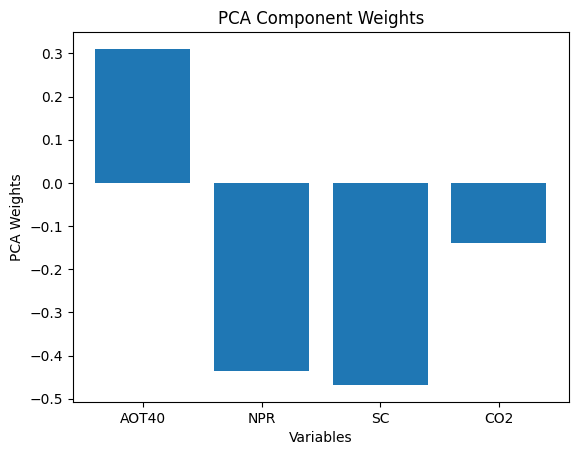

In [3]:
### 2) Principle Component Weights and Bar Chart

pca_weights = pca.components_.T * np.sqrt(explained_variance)  # Calculates the PCA weigths

print("PCA Weights:\n", pca_weights)   #Returns four PCA weights

variables = ["AOT40", "NPR", "SC", "CO2"]   # Placeholder to store the four variables

weights = pca_weights[:,0]   # Isolates the first column of the pca_weight array

# PCA Weight Bar Chart
fig, ax = plt.subplots()

ax.bar(variables, weights)

ax.set_xlabel("Variables")
ax.set_ylabel("PCA Weights")
ax.set_title("PCA Component Weights")


k = 2
Inertia: 1124.8596775368292
Silhouette Score: 0.3060505909744303
k = 3
Inertia: 865.8745518215586
Silhouette Score: 0.2966724054654476
k = 4
Inertia: 685.8631030931938
Silhouette Score: 0.33372386462096626
k = 5
Inertia: 576.4402540582672
Silhouette Score: 0.3332910549244734
k = 6
Inertia: 484.1886540627561
Silhouette Score: 0.31955940527609394
k = 7
Inertia: 431.93070655596733
Silhouette Score: 0.3106898079908438
k = 8
Inertia: 379.1265104349203
Silhouette Score: 0.3263847523794228


Text(0.5, 1.0, 'Silhouette Score for Different k-means')

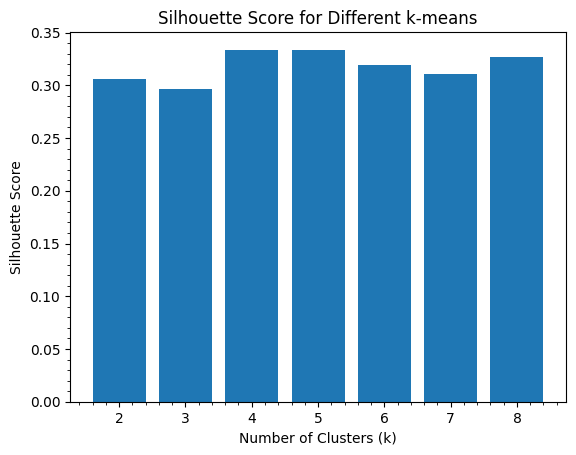

In [4]:
### 3) K-Means Clustering and Bar Chart

# Lists for inertia and silh_values data
inertia = []
silh_values = []

k_values = range(2,9)   # Contains the interval from 2 to 8

for k in k_values:   # Loops through each k_values
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)    # Calculating the k-means

    kmeans_labels = kmeans.fit_predict(scaled_data)   # Fit k-means into data
    
    inertia.append(kmeans.inertia_)   # Adds the current k-means inertia value into the inertia list
    
    silh_score = silhouette_score(scaled_data, kmeans_labels)   # Calculate the silhouette score
    silh_values.append(silh_score)   # Addds the current silhouette score into the silh_value list
    
    print("k =", k)    # Returns k value
    print("Inertia:", kmeans.inertia_)   # Returns k-means Results
    print("Silhouette Score:", silh_score)   # Returns silhouette score

# Create Silhouette Score for Different k-means Bar Chart
fig, ax = plt.subplots()

ax.bar(k_values, silh_values)
ax.minorticks_on()

ax.set_xlabel("Number of Clusters (k)")
ax.set_ylabel("Silhouette Score")
ax.set_title("Silhouette Score for Different k-means")

PC1: 0.5236999335266403
PC2: 0.29038259782695836
Total variance: 0.8140825313535986


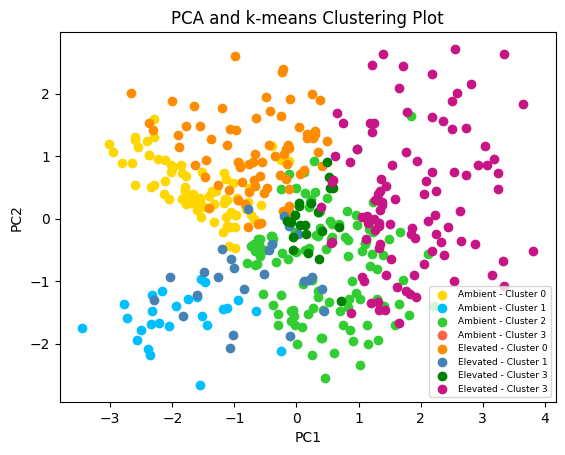

In [10]:
### 4) PC1 and PC2 Visualization

# Create an ambient dataframe
ambient = df[["AOT 40 - Ambient", "NPR - Ambient (umol m-2 s-1)", "SC - Ambient (mol m-2 s-1)", "CO2 - Ambient (umol mol-1)"]].copy()   # Replicate the orginial dataset
ambient.columns = ["AOT40", "NPR", "SC", "CO2"]   # Rename columns
ambient["Treatment"] = "Ambient"    # Every value in this dataset is considered as Ambient Treatment type

# Create an Elevated dataframe
# Repeat process
elevated = df[["AOT 40 - Elevated", "NPR - Elevated (umol m-2 s-1)", "SC - Elevated (mol m-2 s-1)", "CO2 - Elevated (umol mol-1)"]].copy()
elevated.columns = ["AOT40", "NPR", "SC", "CO2"]
elevated["Treatment"] = "Elevated"

# Combine the Ambient and Elevated dataframes
combined_df = pd.concat([ambient, elevated], ignore_index=True)   # Creates a new index in sequential order

numerical_df = combined_df[["AOT40", "NPR", "SC", "CO2"]]   # Create a dataframe without the treatment types column

# PCA Component Analysis
scaled_data2 = scaler.fit_transform(numerical_df)   # Rescales the data

pca2 = PCA(n_components=2)   # Create 2 PCA components

pca2_results = pca2.fit_transform(scaled_data2)   # Rescales the data

PC1 = pca2_results[:, 0]   # Isolate the PC1 from the pca2_results array
PC2 = pca2_results[:, 1]   # Isolate the PC2 from the pca2_results array

# K-Means Clustering
kmeans2 = KMeans(n_clusters=4, n_init=10, random_state=42)     # Calculates the k-means

k_df = combined_df.copy()    # Copy the initial combined dataset

kmeans_labels2 = kmeans2.fit_predict(scaled_data2)   # Rescales the data

k_df["Cluster"] = kmeans_labels2    # Add the cluster into a dataframe

ambient2 = k_df["Treatment"] == "Ambient"    # Identify ambient values
elevated2 = k_df["Treatment"] == "Elevated"   # Identify elevated values
cluster0 = k_df["Cluster"] == 0              # Identify cluster 0
cluster1 = k_df["Cluster"] == 1              # Identify cluster 1
cluster2 = k_df["Cluster"] == 2              # Identify cluster 2
cluster3 = k_df["Cluster"] == 3              # Identify cluster 3

# Create PCA scatter plot
fig, ax = plt.subplots()

# Ambient Observations
# Ambient - Cluster 0 (orange circles)
ax.scatter(PC1[ambient2 & cluster0], PC2[ambient2 & cluster0], color="gold", marker="o", label="Ambient - Cluster 0")

# Ambient - Cluster 1 (orange triangles)
ax.scatter(PC1[ambient2 & cluster1], PC2[ambient2 & cluster1], color="deepskyblue", marker="o", label="Ambient - Cluster 1")

# Ambient - Cluster 2 (orange squares)
ax.scatter(PC1[ambient2 & cluster2], PC2[ambient2 & cluster2], color="limegreen", marker="o", label="Ambient - Cluster 2")

# Ambient - Cluster 3 (orange dimonds)
ax.scatter(PC1[ambient2 & cluster3], PC2[ambient2 & cluster3], color="tomato", marker="o", label="Ambient - Cluster 3")


# Elevated Observations
# Elevated - Cluster 0 (blue circles)
ax.scatter(PC1[elevated2 & cluster0], PC2[elevated2 & cluster0], color="darkorange", marker="o", label="Elevated - Cluster 0")

# Elevated - Cluster 1 (blue triangles)
ax.scatter(PC1[elevated2 & cluster1], PC2[elevated2 & cluster1], color="steelblue", marker="o", label="Elevated - Cluster 1")

# Elevated - Cluster 2 (blue squares)
ax.scatter(PC1[elevated2 & cluster2], PC2[elevated2 & cluster2], color="green", marker="o", label="Elevated - Cluster 3")

# Elevated - Cluster 3 (blue dimonds)
ax.scatter(PC1[elevated2 & cluster3], PC2[elevated2 & cluster3], color="mediumvioletred", marker="o", label="Elevated - Cluster 3")


ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA and K-Means Clustering Plot")
ax.legend(fontsize=6.5)

print("PC1:", pca2.explained_variance_ratio_[0])
print("PC2:", pca2.explained_variance_ratio_[1])
print("Total variance:", pca2.explained_variance_ratio_.sum())